# 01 — Insurance Claims Dataset Audit

**Project:** Insurance Claim Fraud Detection  
**Purpose:** establish a reproducible baseline before cleaning, feature engineering, or model training.

This notebook does not train a model and does not build the interactive application. It inspects the supplied CSV, checks data quality, documents the fraud-label distribution, and saves audit outputs for the thesis.

## How to run
1. Place this notebook in the root of the cloned repository, next to `insurance_claims.csv`.
2. Install dependencies if needed: `pip install pandas numpy matplotlib seaborn jupyter`.
3. Run every cell from top to bottom.
4. Keep the generated `reports/dataset_audit/` files for the EDA and thesis chapters.

**Important:** the repository CSV has an extra `_c39` column and uses `?` as a missing-value marker in some fields. This audit reports these issues rather than silently hiding them.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_PATH = Path("insurance_claims.csv")
OUTPUT_DIR = Path("reports") / "dataset_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Put this notebook beside insurance_claims.csv."
    )

# Convert the dataset's '?' marker to a real missing value (NaN).
df = pd.read_csv(DATA_PATH, na_values=["?"], keep_default_na=True)
df.columns = df.columns.str.strip()

print(f"Dataset loaded: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())

Dataset loaded: C:\Users\chman\Desktop\insurance fraud detection\insurance_claims.csv
Rows: 1,000
Columns: 40


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,insured_sex,insured_education_level,insured_occupation,insured_hobbies,insured_relationship,capital-gains,capital-loss,incident_date,incident_type,collision_type,incident_severity,authorities_contacted,incident_state,incident_city,incident_location,incident_hour_of_the_day,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,MALE,MD,craft-repair,sleeping,husband,53300,0,2015-01-25,Single Vehicle Collision,Side Collision,Major Damage,Police,SC,Columbus,9935 4th Drive,5,1,YES,1,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,MALE,MD,machine-op-inspct,reading,other-relative,0,0,2015-01-21,Vehicle Theft,NaN,Minor Damage,Police,VA,Riverwood,6608 MLK Hwy,8,1,NaN,0,0,NaN,5070,780,780,3510,Mercedes,E400,2007,Y,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,FEMALE,PhD,sales,board-games,own-child,35100,0,2015-02-22,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NY,Columbus,7121 Francis Lane,7,3,NO,2,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,NaN
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,FEMALE,PhD,armed-forces,board-games,unmarried,48900,-62400,2015-01-10,Single Vehicle Collision,Front Collision,Major Damage,Police,OH,Arlington,6956 Maple Drive,5,1,NaN,1,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,NaN
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,MALE,Associate,sales,board-games,unmarried,66000,-46000,2015-02-17,Vehicle Theft,NaN,Minor Damage,NaN,NY,Arlington,3041 3rd Ave,20,1,NO,0,1,NO,6500,1300,650,4550,Accura,RSX,2009,N,NaN


## 1. Dataset structure and target definition

The prediction target is `fraud_reported`: `Y` means the dataset labels the claim as fraudulent, and `N` means it labels the claim as non-fraudulent. We preserve the original label in the raw data and create a numeric target only inside the later modeling workflow.

In [2]:
TARGET = "fraud_reported"

if TARGET not in df.columns:
    raise KeyError(f"Expected target column {TARGET!r} was not found.")

structure = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(dtype) for dtype in df.dtypes],
    "non_null_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "missing_percent": (df.isna().mean().values * 100).round(2),
    "unique_values_including_na": [df[col].nunique(dropna=False) for col in df.columns],
})

display(structure)
structure.to_csv(OUTPUT_DIR / "column_structure.csv", index=False)
print("Target labels found:", sorted(df[TARGET].dropna().astype(str).unique().tolist()))
print("Target missing values:", int(df[TARGET].isna().sum()))

,column,dtype,non_null_count,missing_count,missing_percent,unique_values_including_na
0,months_as_customer,int64,1000,0,0.0,391
1,age,int64,1000,0,0.0,46
2,policy_number,int64,1000,0,0.0,1000
3,policy_bind_date,str,1000,0,0.0,951
4,policy_state,str,1000,0,0.0,3
5,policy_csl,str,1000,0,0.0,3
6,policy_deductable,int64,1000,0,0.0,3
7,policy_annual_premium,float64,1000,0,0.0,991
8,umbrella_limit,int64,1000,0,0.0,11
9,insured_zip,int64,1000,0,0.0,995


Target labels found: ['N', 'Y']
Target missing values: 0


## 2. Data-quality checks

We check duplicated records, missing values, columns containing only missing values, unexpected target labels, and repeated identifier-like fields. A missing marker is not automatically a reason to delete a row; the treatment will be decided during preprocessing.

In [3]:
all_missing_columns = df.columns[df.isna().all()].tolist()
missing_by_column = (
    df.isna().sum().rename("missing_count").to_frame()
      .assign(missing_percent=lambda x: (x["missing_count"] / len(df) * 100).round(2))
      .query("missing_count > 0")
      .sort_values("missing_count", ascending=False)
)

quality_checks = {
    "row_count": int(len(df)),
    "column_count": int(df.shape[1]),
    "duplicate_rows": int(df.duplicated().sum()),
    "all_missing_columns": all_missing_columns,
    "total_missing_cells": int(df.isna().sum().sum()),
    "target_missing": int(df[TARGET].isna().sum()),
    "target_labels": sorted(df[TARGET].dropna().astype(str).unique().tolist()),
}
print(json.dumps(quality_checks, indent=2))
display(missing_by_column)
missing_by_column.to_csv(OUTPUT_DIR / "missing_values_by_column.csv")

identifier_candidates = [c for c in ["policy_number", "insured_zip", "incident_location"] if c in df.columns]
identifier_summary = pd.DataFrame({
    "column": identifier_candidates,
    "unique_values": [df[c].nunique(dropna=True) for c in identifier_candidates],
    "unique_ratio": [round(df[c].nunique(dropna=True) / len(df), 3) for c in identifier_candidates],
})
display(identifier_summary)

{
  "row_count": 1000,
  "column_count": 40,
  "duplicate_rows": 0,
  "all_missing_columns": [
    "_c39"
  ],
  "total_missing_cells": 1972,
  "target_missing": 0,
  "target_labels": [
    "N",
    "Y"
  ]
}


,missing_count,missing_percent
_c39,1000,100.0
property_damage,360,36.0
police_report_available,343,34.3
collision_type,178,17.8
authorities_contacted,91,9.1


,column,unique_values,unique_ratio
0,policy_number,1000,1.000
1,insured_zip,995,0.995
2,incident_location,1000,1.000


## 3. Fraud-label distribution

Accuracy can be misleading when the classes are not equally represented. Record counts and percentages for both classes. Later model evaluation will emphasize fraud-class precision, recall, F1-score, PR-AUC, ROC-AUC, and the confusion matrix—not accuracy alone.

,fraud_reported,count,percentage
0,N,753,75.3
1,Y,247,24.7


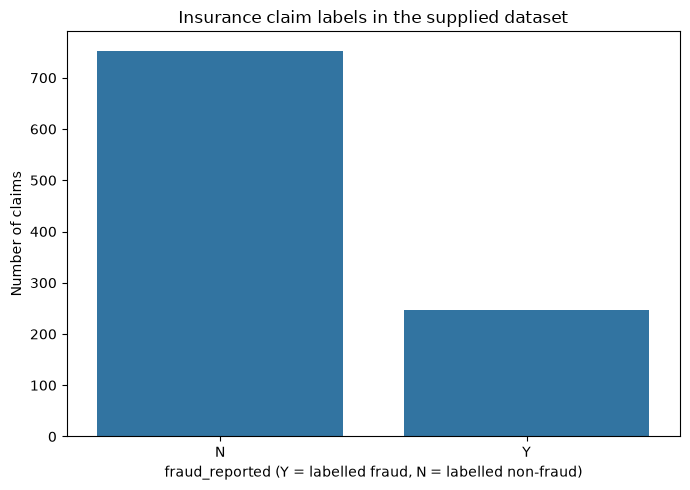

In [4]:
target_counts = df[TARGET].value_counts(dropna=False).rename_axis("fraud_reported").reset_index(name="count")
target_counts["percentage"] = (target_counts["count"] / len(df) * 100).round(2)
display(target_counts)
target_counts.to_csv(OUTPUT_DIR / "target_distribution.csv", index=False)

plt.figure(figsize=(7, 5))
sns.barplot(data=target_counts, x="fraud_reported", y="count")
plt.title("Insurance claim labels in the supplied dataset")
plt.xlabel("fraud_reported (Y = labelled fraud, N = labelled non-fraud)")
plt.ylabel("Number of claims")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "target_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Numeric and categorical feature overview

This section is descriptive only. Do not interpret a group with a higher fraud rate as proof of fraud or as evidence of causation. Small group sizes can produce unstable percentages.

In [5]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()
print(f"Numeric columns ({len(numeric_columns)}): {numeric_columns}")
print(f"Non-numeric columns ({len(categorical_columns)}): {categorical_columns}")

if numeric_columns:
    numeric_summary = df[numeric_columns].describe().T
    display(numeric_summary)
    numeric_summary.to_csv(OUTPUT_DIR / "numeric_summary.csv")

categorical_summary = pd.DataFrame({
    "column": categorical_columns,
    "unique_non_missing": [df[c].nunique(dropna=True) for c in categorical_columns],
    "missing_count": [df[c].isna().sum() for c in categorical_columns],
    "most_frequent_value": [df[c].mode(dropna=True).iloc[0] if not df[c].mode(dropna=True).empty else np.nan for c in categorical_columns],
    "most_frequent_count": [df[c].value_counts(dropna=True).iloc[0] if not df[c].value_counts(dropna=True).empty else 0 for c in categorical_columns],
})
display(categorical_summary)
categorical_summary.to_csv(OUTPUT_DIR / "categorical_summary.csv", index=False)

Numeric columns (19): ['months_as_customer', 'age', 'policy_number', 'policy_deductable', 'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'capital-gains', 'capital-loss', 'incident_hour_of_the_day', 'number_of_vehicles_involved', 'bodily_injuries', 'witnesses', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'auto_year', '_c39']
Non-numeric columns (21): ['policy_bind_date', 'policy_state', 'policy_csl', 'insured_sex', 'insured_education_level', 'insured_occupation', 'insured_hobbies', 'insured_relationship', 'incident_date', 'incident_type', 'collision_type', 'incident_severity', 'authorities_contacted', 'incident_state', 'incident_city', 'incident_location', 'property_damage', 'police_report_available', 'auto_make', 'auto_model', 'fraud_reported']


,count,mean,std,min,25%,50%,75%,max
months_as_customer,1000.0,2.039540e+02,1.151132e+02,0.00,115.7500,199.5,276.250,479.00
age,1000.0,3.894800e+01,9.140287e+00,19.00,32.0000,38.0,44.000,64.00
policy_number,1000.0,5.462386e+05,2.570630e+05,100804.00,335980.2500,533135.0,759099.750,999435.00
policy_deductable,1000.0,1.136000e+03,6.118647e+02,500.00,500.0000,1000.0,2000.000,2000.00
policy_annual_premium,1000.0,1.256406e+03,2.441674e+02,433.33,1089.6075,1257.2,1415.695,2047.59
umbrella_limit,1000.0,1.101000e+06,2.297407e+06,-1000000.00,0.0000,0.0,0.000,10000000.00
insured_zip,1000.0,5.012145e+05,7.170161e+04,430104.00,448404.5000,466445.5,603251.000,620962.00
capital-gains,1000.0,2.512610e+04,2.787219e+04,0.00,0.0000,0.0,51025.000,100500.00
capital-loss,1000.0,-2.679370e+04,2.810410e+04,-111100.00,-51500.0000,-23250.0,0.000,0.00
incident_hour_of_the_day,1000.0,1.164400e+01,6.951373e+00,0.00,6.0000,12.0,17.000,23.00


,column,unique_non_missing,missing_count,most_frequent_value,most_frequent_count
0,policy_bind_date,951,0,1992-04-28,3
1,policy_state,3,0,OH,352
2,policy_csl,3,0,250/500,351
3,insured_sex,2,0,FEMALE,537
4,insured_education_level,7,0,JD,161
5,insured_occupation,14,0,machine-op-inspct,93
6,insured_hobbies,20,0,reading,64
7,insured_relationship,6,0,own-child,183
8,incident_date,60,0,2015-02-02,28
9,incident_type,4,0,Multi-vehicle Collision,419


## 5. Initial consistency checks

The three claim-component columns are compared with `total_claim_amount`. We quantify the difference rather than assuming the records are perfectly consistent. Date columns are parsed to identify invalid values.

In [6]:
claim_parts = ["injury_claim", "property_claim", "vehicle_claim"]
if all(c in df.columns for c in claim_parts + ["total_claim_amount"]):
    component_sum = df[claim_parts].sum(axis=1, min_count=len(claim_parts))
    difference = df["total_claim_amount"] - component_sum
    print("Rows with all claim components available:", int(difference.notna().sum()))
    print("Rows where total differs from component sum:", int((difference.dropna() != 0).sum()))
    print("Largest absolute difference:", float(difference.abs().max()))
    display(pd.DataFrame({"total_claim_amount": df["total_claim_amount"], "component_sum": component_sum, "difference": difference}).head(10))

for date_col in ["policy_bind_date", "incident_date"]:
    if date_col in df.columns:
        parsed = pd.to_datetime(df[date_col], errors="coerce")
        print(f"{date_col}: invalid/unparsed dates = {int(parsed.isna().sum())}")

for col in ["age", "months_as_customer", "incident_hour_of_the_day", "number_of_vehicles_involved", "bodily_injuries", "witnesses", "auto_year"]:
    if col in df.columns:
        print(f"{col}: min={df[col].min()}, max={df[col].max()}")

Rows with all claim components available: 1000
Rows where total differs from component sum: 0
Largest absolute difference: 0.0


,total_claim_amount,component_sum,difference
0,71610,71610,0
1,5070,5070,0
2,34650,34650,0
3,63400,63400,0
4,6500,6500,0
5,64100,64100,0
6,78650,78650,0
7,51590,51590,0
8,27700,27700,0
9,42300,42300,0


policy_bind_date: invalid/unparsed dates = 0
incident_date: invalid/unparsed dates = 0
age: min=19, max=64
months_as_customer: min=0, max=479
incident_hour_of_the_day: min=0, max=23
number_of_vehicles_involved: min=1, max=4
bodily_injuries: min=0, max=2
witnesses: min=0, max=3
auto_year: min=1995, max=2015


## 6. Fraud-rate summaries for selected categorical fields

These are exploratory summaries only. Group sizes are shown alongside fraud rates so tiny categories are not mistaken for strong patterns.

In [7]:
selected_categorical = [
    c for c in ["incident_type", "incident_severity", "collision_type", "authorities_contacted",
                "property_damage", "police_report_available", "insured_sex", "policy_state"]
    if c in df.columns
]

for col in selected_categorical:
    tmp = df[[col, TARGET]].dropna().copy()
    tmp["fraud_binary"] = tmp[TARGET].map({"Y": 1, "N": 0})
    summary = (tmp.groupby(col, dropna=False)
                  .agg(claim_count=(TARGET, "size"), fraud_count=("fraud_binary", "sum"), fraud_rate=("fraud_binary", "mean"))
                  .assign(fraud_rate_percent=lambda x: (x["fraud_rate"] * 100).round(2))
                  .drop(columns="fraud_rate")
                  .sort_values("claim_count", ascending=False))
    print(f"\n--- {col} ---")
    display(summary)
    summary.to_csv(OUTPUT_DIR / f"fraud_rate_by_{col}.csv")


--- incident_type ---


,claim_count,fraud_count,fraud_rate_percent
incident_type,,,
Multi-vehicle Collision,419,114,27.21
Single Vehicle Collision,403,117,29.03
Vehicle Theft,94,8,8.51
Parked Car,84,8,9.52



--- incident_severity ---


,claim_count,fraud_count,fraud_rate_percent
incident_severity,,,
Minor Damage,354,38,10.73
Total Loss,280,36,12.86
Major Damage,276,167,60.51
Trivial Damage,90,6,6.67



--- collision_type ---


,claim_count,fraud_count,fraud_rate_percent
collision_type,,,
Rear Collision,292,91,31.16
Side Collision,276,70,25.36
Front Collision,254,70,27.56


... (6 outputs left out)


--- insured_sex ---


,claim_count,fraud_count,fraud_rate_percent
insured_sex,,,
FEMALE,537,126,23.46
MALE,463,121,26.13



--- policy_state ---


,claim_count,fraud_count,fraud_rate_percent
policy_state,,,
OH,352,91,25.85
IL,338,77,22.78
IN,310,79,25.48


## 7. Save the audit summary

Review the generated tables and retain the JSON file as a reproducible snapshot. Do not alter the original CSV; cleaning will happen in a separate preprocessing notebook.

In [8]:
audit_summary = {
    **quality_checks,
    "target_distribution": {
        str(row["fraud_reported"]): {"count": int(row["count"]), "percentage": float(row["percentage"])}
        for _, row in target_counts.iterrows()
    },
    "numeric_columns": numeric_columns,
    "categorical_columns": categorical_columns,
    "identifier_candidates": identifier_summary.to_dict(orient="records"),
}

with open(OUTPUT_DIR / "dataset_audit_summary.json", "w", encoding="utf-8") as f:
    json.dump(audit_summary, f, indent=2, default=str)

print(f"Audit outputs saved in: {OUTPUT_DIR.resolve()}")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)

Audit outputs saved in: C:\Users\chman\Desktop\insurance fraud detection\reports\dataset_audit
 - categorical_summary.csv
 - column_structure.csv
 - dataset_audit_summary.json
 - fraud_rate_by_authorities_contacted.csv
 - fraud_rate_by_collision_type.csv
 - fraud_rate_by_incident_severity.csv
 - fraud_rate_by_incident_type.csv
 - fraud_rate_by_insured_sex.csv
 - fraud_rate_by_police_report_available.csv
 - fraud_rate_by_policy_state.csv
 - fraud_rate_by_property_damage.csv
 - missing_values_by_column.csv
 - numeric_summary.csv
 - target_distribution.csv
 - target_distribution.png


## 8. Research notes to carry into the thesis

Complete these notes using the actual output:

- Number of claim records: **[fill from output]**
- Number of original CSV columns: **[fill from output]**
- Fraud-labelled records (`Y`): **[fill from output]**
- Non-fraud-labelled records (`N`): **[fill from output]**
- Missing-value markers / missing fields: **[fill from output]**
- Empty or redundant columns: **[fill from output]**
- Duplicate rows: **[fill from output]**
- Important consistency issues: **[fill from output]**

### Preliminary limitations to acknowledge

1. This is a relatively small, publicly circulated sample dataset; results should not be generalized to all insurers or current claim populations.
2. The target represents the labels supplied with the dataset. It is not independent proof of fraud.
3. The dataset includes personal and location-like fields. Identifiers and granular location data need careful justification or exclusion.
4. Some claim and incident fields may only be available after parts of the claim investigation. The intended prediction time must be defined before deciding whether to use them.
5. Model results must be evaluated on a held-out, stratified test set, with all preprocessing learned only from training data.

**End of Step 1.** Do not begin model training yet. Save the audit outputs and share the printed summary/results so we can design the cleaning and preprocessing strategy based on evidence.